# Multiple Linear Regression

## Learning Objectives

By the end of this notebook, you will be able to:

- Understand the difference between simple and multiple linear regression.
- Build a model using multiple input features.
- Calculate predictions using the hypothesis equation.
- Implement the half mean squared-error cost function.
- Calculate gradients for the intercept and feature coefficients.
- Train a multiple linear regression model using gradient descent.
- Evaluate and visualize the model's predictions.

**Dataset:** A small illustrative house-price dataset.

**Features:** Number of rooms, house size, and an encoded location score.

**Target:** House price in illustrative units.

The dataset is synthetic and intended for learning, not real-world price estimation.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
data = pd.DataFrame({
    "rooms": [2, 3, 3, 4, 4, 5, 2, 5],
    "size_100sqft": [8, 10, 12, 14, 16, 18, 9, 20],
    "location_score": [0, 0, 1, 0, 1, 1, 1, 0],
    "price": [90, 115, 145, 135, 170, 195, 115, 185]
})

display(data)

print("Dataset shape:", data.shape)
print("Number of input features:", data.shape[1] - 1)

,rooms,size_100sqft,location_score,price
0,2,8,0,90
1,3,10,0,115
2,3,12,1,145
3,4,14,0,135
4,4,16,1,170
5,5,18,1,195
6,2,9,1,115
7,5,20,0,185


Dataset shape: (8, 4)
Number of input features: 3


## 1. Separate Features and Target

The independent features are:

- `rooms`
- `size_100sqft`
- `location_score`

The dependent variable is `price`.

The location score is already numerically encoded in this illustrative dataset. Real categorical location data may require an appropriate encoding strategy.

We separate the inputs into $X$ and the target into $y$.


In [3]:
feature_names = [
    "rooms",
    "size_100sqft",
    "location_score"
]

X = data[feature_names].to_numpy(dtype=float)
y = data["price"].to_numpy(dtype=float)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst three feature rows:")
print(X[:3])

print("\nFirst three target values:")
print(y[:3])


X shape: (8, 3)
y shape: (8,)

First three feature rows:
[[ 2.  8.  0.]
 [ 3. 10.  0.]
 [ 3. 12.  1.]]

First three target values:
[ 90. 115. 145.]


## 2. Multiple Linear Regression Hypothesis

For three input features, the hypothesis is:

$$
h_\theta(x)=\theta_0+\theta_1x_1+\theta_2x_2+\theta_3x_3
$$

- $\theta_0$: Intercept
- $\theta_1$: Coefficient for rooms
- $\theta_2$: Coefficient for house size
- $\theta_3$: Coefficient for location score

The intercept is shared by the model. Every feature has its own coefficient.


In [4]:
# Standardize each feature using the training dataset.
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

X_scaled = (X - X_mean) / X_std

# Add a column of ones for the intercept.
X_design = np.column_stack([
    np.ones(len(X_scaled)),
    X_scaled
])

m, n_parameters = X_design.shape

print("Design matrix shape:", X_design.shape)
print("Parameters including intercept:", n_parameters)

display(pd.DataFrame(
    X_scaled,
    columns=[f"{name}_scaled" for name in feature_names]
).round(3))


Design matrix shape: (8, 4)
Parameters including intercept: 4


,rooms_scaled,size_100sqft_scaled,location_score_scaled
0,-1.342,-1.314,-1.0
1,-0.447,-0.825,-1.0
2,-0.447,-0.336,1.0
3,0.447,0.153,-1.0
4,0.447,0.642,1.0
5,1.342,1.131,1.0
6,-1.342,-1.069,1.0
7,1.342,1.620,-1.0


## 3. Calculate Predictions

Using the design matrix, predictions can be calculated as:

$$
\hat{y}=X_{\text{design}}\theta
$$

The parameter vector contains the intercept followed by the feature coefficients.

Feature scaling is used here to help gradient descent work with features of different magnitudes. The learned coefficients therefore correspond to the scaled features, rather than the original feature units.


In [5]:
def predict(X_design, theta):
    return X_design @ theta


# Initialize the intercept at the target mean.
# Initialize all feature coefficients at zero.
theta = np.zeros(X_design.shape[1], dtype=float)
theta[0] = y.mean()

initial_predictions = predict(X_design, theta)

print("Initial parameters:", theta)
print("Initial predictions:", initial_predictions.round(2))


Initial parameters: [143.75   0.     0.     0.  ]
Initial predictions: [143.75 143.75 143.75 143.75 143.75 143.75 143.75 143.75]


## 4. Calculate the Cost

We use the half mean squared-error cost:

$$
J(\theta)=\frac{1}{2m}
\sum_{i=1}^{m}(\hat{y}^{(i)}-y^{(i)})^2
$$

A lower cost indicates smaller squared prediction errors on the dataset.

The factor $1/2$ simplifies differentiation and does not change the location of the minimum.


In [6]:
def compute_cost(X_design, y, theta):
    predictions = predict(X_design, theta)
    errors = predictions - y

    m = len(y)
    return np.sum(errors ** 2) / (2 * m)


initial_cost = compute_cost(X_design, y, theta)

print(f"Initial cost: {initial_cost:.4f}")


Initial cost: 602.3438


## 5. Gradient Calculation

The gradient for the intercept is:

$$
\frac{\partial J}{\partial\theta_0}
=\frac{1}{m}\sum_{i=1}^{m}(\hat{y}^{(i)}-y^{(i)})
$$

For each feature coefficient $\theta_j$:

$$
\frac{\partial J}{\partial\theta_j}
=\frac{1}{m}\sum_{i=1}^{m}
(\hat{y}^{(i)}-y^{(i)})x_j^{(i)}
$$

Using matrix notation, all gradients can be computed together:

$$
\nabla J(\theta)=
\frac{1}{m}X_{\text{design}}^T(\hat{y}-y)
$$

The intercept column consists of ones, so its gradient is included automatically.


In [7]:
def compute_gradient(X_design, y, theta):
    predictions = predict(X_design, theta)
    errors = predictions - y

    m = len(y)
    gradients = (X_design.T @ errors) / m

    return gradients


gradients = compute_gradient(X_design, y, theta)

gradient_table = pd.DataFrame({
    "Parameter": ["theta_0"] + [
        f"theta_{i}" for i in range(1, len(theta))
    ],
    "Gradient": gradients
})

display(gradient_table.round(4))


,Parameter,Gradient
0,theta_0,0.0000
1,theta_1,-31.8640
2,theta_2,-33.1157
3,theta_3,-12.5000


## 6. Train the Model Using Gradient Descent

The parameter update rule is:

$$
\theta_j\leftarrow
\theta_j-\alpha\frac{\partial J}{\partial\theta_j}
$$

All gradients are calculated using the same current parameter vector. The parameters are then updated together.

We record the cost at every iteration to observe the optimization process.


In [8]:
def gradient_descent(
    X_design,
    y,
    learning_rate=0.1,
    iterations=2000
):
    theta = np.zeros(X_design.shape[1], dtype=float)
    theta[0] = y.mean()

    history = []

    for iteration in range(iterations + 1):
        cost = compute_cost(X_design, y, theta)

        history.append({
            "iteration": iteration,
            "cost": cost
        })

        if iteration == iterations:
            break

        gradients = compute_gradient(X_design, y, theta)

        # Simultaneous update using the current gradients.
        theta = theta - learning_rate * gradients

    return theta, pd.DataFrame(history)


theta, history = gradient_descent(
    X_design,
    y,
    learning_rate=0.1,
    iterations=2000
)

print("Learned parameters:")
print(f"Intercept (scaled-feature model): {theta[0]:.4f}")

for name, coefficient in zip(feature_names, theta[1:]):
    print(f"{name} coefficient: {coefficient:.4f}")

print(f"\nInitial cost: {history['cost'].iloc[0]:.4f}")
print(f"Final cost:   {history['cost'].iloc[-1]:.4f}")


Learned parameters:
Intercept (scaled-feature model): 143.7500
rooms coefficient: 11.5285
size_100sqft coefficient: 20.9599
location_score coefficient: 10.5787

Initial cost: 602.3438
Final cost:   5.5007


## 7. Compare Actual and Predicted Prices

After training, use the learned parameters to predict prices for the dataset.

We will compare the predictions against the actual target values using:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)

These metrics help us understand the magnitude of prediction errors in the target's units.


In [9]:
predictions = predict(X_design, theta)
errors = predictions - y

mae = np.mean(np.abs(errors))
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)

results = pd.DataFrame({
    "Actual Price": y,
    "Predicted Price": predictions,
    "Residual": y - predictions
})

display(results.round(2))

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")


,Actual Price,Predicted Price,Residual
0,90.0,90.16,-0.16
1,115.0,110.72,4.28
2,145.0,142.13,2.87
3,135.0,141.53,-6.53
4,170.0,172.93,-2.93
5,195.0,193.49,1.51
6,115.0,116.45,-1.45
7,185.0,182.58,2.42


MAE:  2.7683
MSE:  11.0014
RMSE: 3.3168


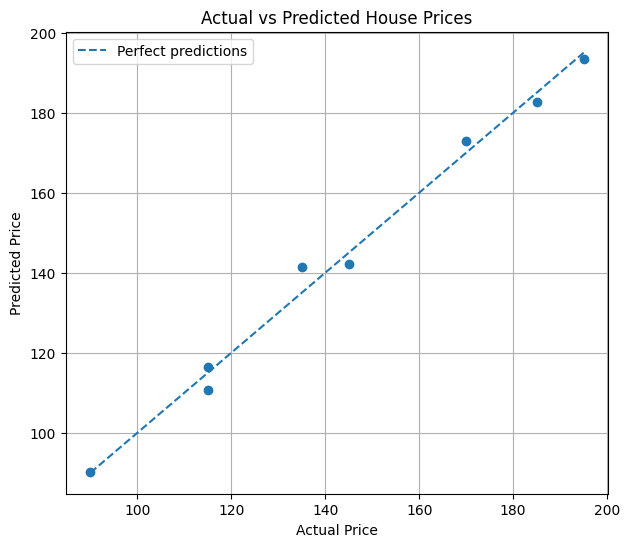

In [10]:
plt.figure(figsize=(7, 6))

plt.scatter(y, predictions)

minimum = min(y.min(), predictions.min())
maximum = max(y.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect predictions"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True)
plt.show()


## 8. Understanding the Learned Parameters

The learned coefficients describe how the model uses each feature to predict the target.

Because we standardized the input features:

- The intercept corresponds to the prediction when all standardized features equal zero.
- Each coefficient represents the change in predicted price for a one-unit increase in its standardized feature, holding the other features constant.

These coefficients are associations learned from the training data. They do not, by themselves, establish causal relationships.

For a model intended for real-world use, evaluation on unseen data is important.


## 9. Self-Check Questions

1. What is the main difference between simple and multiple linear regression?
2. Why does multiple linear regression still have only one intercept?
3. How many parameters does a model with three features have?
4. Why do we calculate a separate gradient for each parameter?
5. Why do we standardize the features in this notebook?
6. What does a decreasing cost curve indicate?
7. What is the difference between MAE and RMSE?
8. Why should a real model be evaluated on unseen data?

### Answers

1. Simple linear regression uses one input feature; multiple linear regression uses two or more.
2. The model has one constant intercept term regardless of the number of features.
3. Four: one intercept and three feature coefficients.
4. Each parameter affects the prediction differently, so it has its own partial derivative.
5. Scaling helps gradient descent handle features with different magnitudes more effectively.
6. The optimization process is reducing the cost on the training dataset.
7. MAE averages absolute errors; RMSE takes the square root of the mean squared errors and penalizes large errors more strongly.
8. Unseen data helps assess how well the model generalizes beyond its training examples.